# Laboratorio 1

### Librerías

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
from scipy.stats import boxcox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sktime.forecasting.naive import NaiveForecaster
from prophet import Prophet
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from scipy.stats import linregress
import matplotlib.dates as mdates

In [15]:
#pip install sktime

### Importación de datos.

In [16]:
df = pd.read_csv('DATOS_LIMPIOS.csv')
df.head(2)

,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero,Fecha
0,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.0,2009-01-01
1,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.0,2009-01-01


### Serie de tiempo.

In [17]:
df_filtro = df[(df['Tipo de Viajero'].isin(['Excursionista', 'Turista']) & (df['País'] == 'El Salvador'))]
df_fecha = df_filtro.groupby('Fecha')['Viajero'].sum().round(0).astype(int)
serie = df_fecha.to_frame('Viajero')
serie = serie.sort_values(by='Fecha', ascending=True)
serie.index = pd.to_datetime(serie.index)
serie.index = serie.index.to_period('M')

### Estimando la tendencia en la pandemia.

In [18]:
inicio = pd.Period('2020-03', freq='M')
fin = pd.Period('2022-12', freq='M')

In [19]:
y_train = serie.loc[serie.index < inicio, 'Viajero']
modelo = NaiveForecaster(strategy='last', sp=12)
modelo.fit(y_train)
fh = range(len(y_train) + 1, len(y_train) + len(pd.period_range(inicio, fin, freq='M')) + 1)
predicciones = modelo.predict(fh=fh)

# Reindexando si no existen
serie = serie.reindex(serie.index.union(pd.period_range(inicio, fin, freq='M')), fill_value=0)
serie.loc[inicio:fin, 'Viajero'] = predicciones.to_numpy()
serie['Viajero'] = serie['Viajero'].round().astype(int)
serie.index = serie.index.to_timestamp()

### Separación de datos.

In [20]:
filas, columnas = serie.shape
fil_entrenamiento = int(filas * 0.7)
entrenamiento = serie.iloc[:fil_entrenamiento+1]
prueba = serie.iloc[fil_entrenamiento+1:]

In [21]:
serie.head(2)

,Viajero
2009-01-01,16569
2009-02-01,17126


### Gráfico de descomposición de la serie temporal.

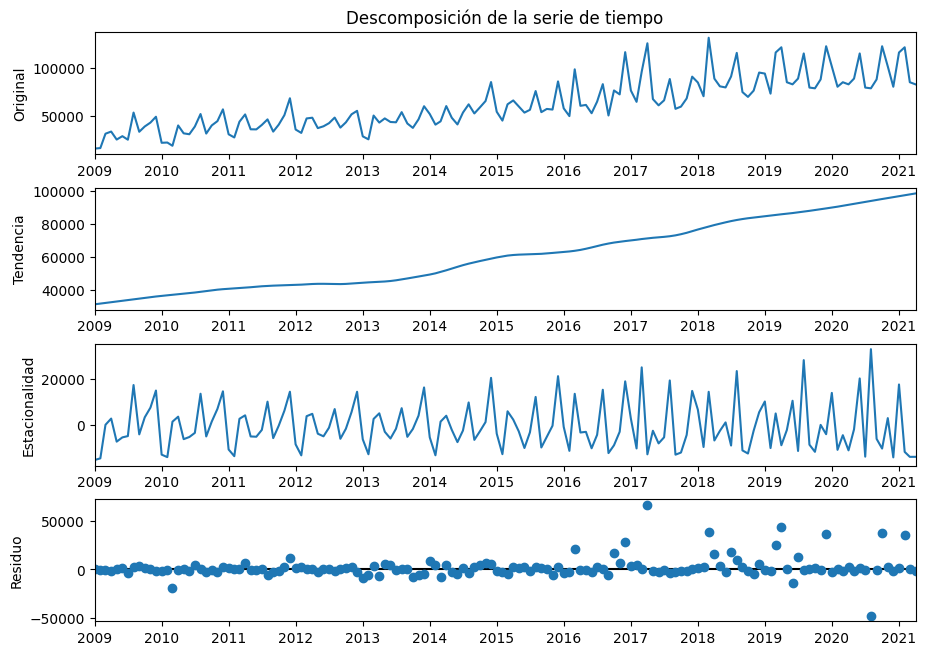

In [22]:
stl = STL(entrenamiento, period=12, robust=True)

descomposicion = stl.fit()
fig = descomposicion.plot()
fig.set_size_inches(10, 7)
axes = fig.axes

for ax in axes:
    ax.tick_params(axis='x', labelbottom=True)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[0].set_title('Descomposición de la serie de tiempo')
axes[0].set_ylabel('Original')
axes[1].set_ylabel('Tendencia')
axes[2].set_ylabel('Estacionalidad')
axes[3].set_ylabel('Residuo')
plt.show()

### Tendencia de toda la serie.

In [23]:
x = range(len(serie))
tendencia = linregress(x, serie['Viajero']).slope
tendencia

np.float64(498.18154606680423)

### Valor alpha a utilizar.

In [24]:
alpha = 0.05

### Verificación de estacionariedad en media (Serie original).

$\alpha = 0.05$

$\textbf{ADF}$  
$H_0:$ La serie no es estacionaria en media.  
$H_a:$ La serie es estacionaria en media.

$\textbf{KPSS}$   
$H_0:$ La serie es estacionaria en media.  
$H_a:$ La serie no es estacionaria en media.

In [25]:
def estacionariedad_media(datos, alpha):
    adf = adfuller(datos, regression="c")[1]
    kpss_test = kpss(datos, regression="c", nlags="auto")[1]

    if adf < alpha:
        texto_1 = f'Prueba ADF: Se rechaza la hipótesis nula, ya que el valor p = {adf} < alpha = {alpha}. La serie es estacionaria en media.'
    else:
        texto_1 = f'Prueba ADF: No se rechaza la hipótesis nula, ya que el valor p = {adf} >= alpha = {alpha}. La serie se considera no estacionaria en media.'

    if kpss_test < alpha:
        texto_2 = f'Prueba KPSS: Se rechaza la hipótesis nula, ya que el valor p = {kpss_test} < alpha = {alpha}. La serie no es estacionaria en media.'
    else:
        texto_2 = f'Prueba KPSS: No se rechaza la hipótesis nula, ya que el valor p = {kpss_test} >= alpha = {alpha}. La serie se considera estacionaria en media.'

    print(texto_1)
    print(texto_2)

    if (adf <= alpha and kpss_test <= alpha) or (adf > alpha and kpss_test > alpha):
        print('Las pruebas no coinciden, pero se realizará diferenciación, ya que una muestra la no estacionariedad de la media.')

estacionariedad_media(serie, alpha)

Prueba ADF: No se rechaza la hipótesis nula, ya que el valor p = 0.8860291988761404 >= alpha = 0.05. La serie se considera no estacionaria en media.
Prueba KPSS: Se rechaza la hipótesis nula, ya que el valor p = 0.01 < alpha = 0.05. La serie no es estacionaria en media.


C:\Users\ricro\AppData\Local\Temp\ipykernel_24340\1874529149.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_test = kpss(datos, regression="c", nlags="auto")[1]


### Verificación de estacionariedad en media (Serie diferenciada).

In [26]:
estacionariedad_media(entrenamiento.diff()[1:], alpha)

Prueba ADF: Se rechaza la hipótesis nula, ya que el valor p = 4.942731836373002e-13 < alpha = 0.05. La serie es estacionaria en media.
Prueba KPSS: No se rechaza la hipótesis nula, ya que el valor p = 0.1 >= alpha = 0.05. La serie se considera estacionaria en media.


C:\Users\ricro\AppData\Local\Temp\ipykernel_24340\1874529149.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_test = kpss(datos, regression="c", nlags="auto")[1]


### Verificación de estacionariedad en varianza (Serie original).

$\alpha = 0.05$

$\textbf{ARCH}$  
$H_0:$ La serie es estacionaria en varianza.  
$H_a:$ La serie no es estacionaria en varianza.

In [27]:
def estacionariedad_varianza(datos, alpha):
    arch = het_arch(datos)[1]

    if arch < alpha:
        texto_1 = f'Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = {arch} < alpha = {alpha}. La serie no es estacionaria en varianza. Se hará una transformación.'
    else:
        texto_1 = f'Prueba ARCH: No se rechaza la hipótesis nula, ya que el valor p = {arch} >= alpha = {alpha}. La serie se considera estacionaria en varianza.'

    print(texto_1)
estacionariedad_varianza(entrenamiento, alpha)

Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = 2.653169195958708e-15 < alpha = 0.05. La serie no es estacionaria en varianza. Se hará una transformación.


### Verificación de estacionariedad en varianza (Serie box cox).

In [28]:
entrenamiento_box_cox, lambda_optimo = boxcox(entrenamiento['Viajero'])
estacionariedad_varianza(entrenamiento_box_cox, alpha)

Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = 1.2575083596221004e-18 < alpha = 0.05. La serie no es estacionaria en varianza. Se hará una transformación.


No se puede quitar la no estacionariedad de la varianza, se seguirá con el modelaje, pero se recalca este problema.

### Transformaciones hechas.

In [29]:
entrenamiento_transformado = entrenamiento

### Elección de parámetro d.

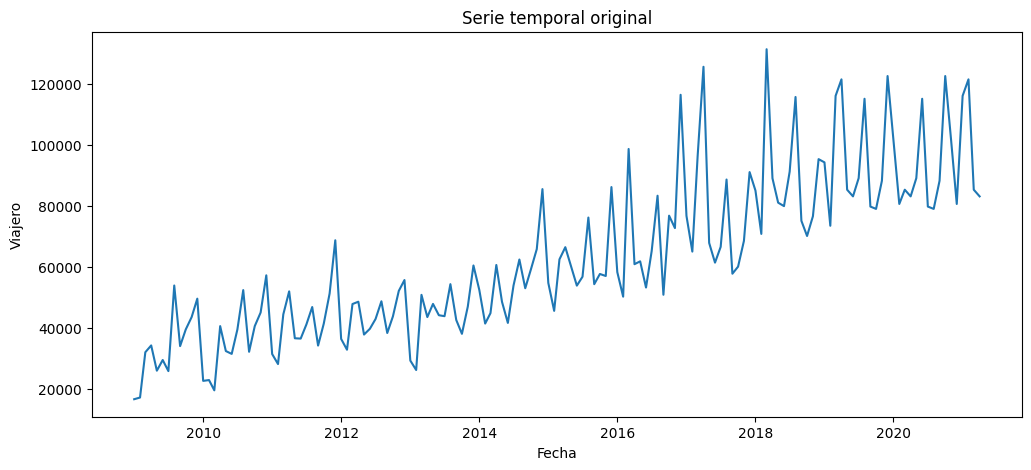

In [30]:
y = entrenamiento
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.title("Serie temporal original")
plt.xlabel("Fecha")
plt.ylabel("Viajero")
plt.show()

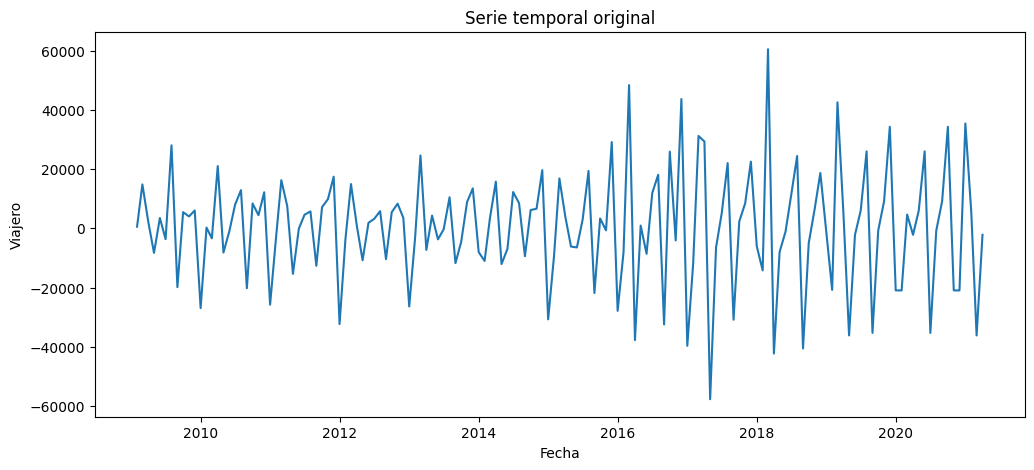

In [31]:
y = entrenamiento.diff(1).dropna()
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.title("Serie temporal original")
plt.xlabel("Fecha")
plt.ylabel("Viajero")
plt.show()

La serie logra estabilizarse en media con una diferencia regular.

### Elección del parámetro p y q.

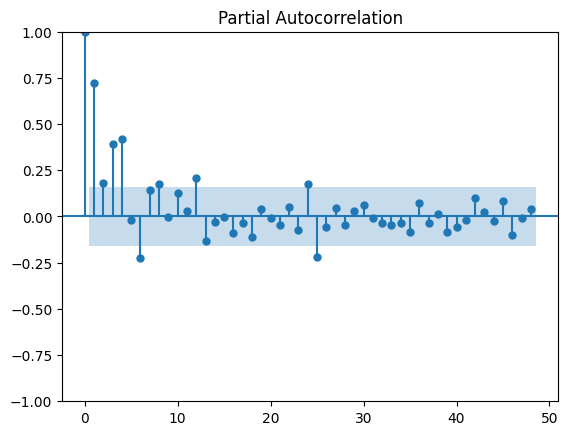

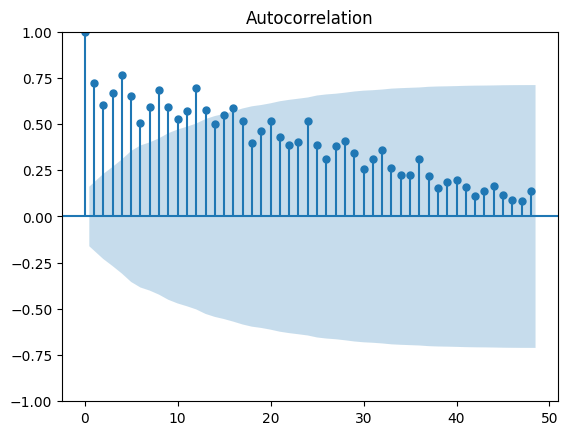

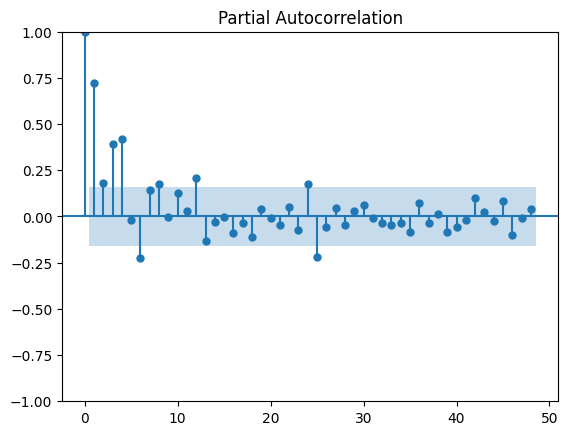

In [32]:
plot_acf(entrenamiento_transformado, lags=48)
plot_pacf(entrenamiento_transformado, lags=48)

El PACF cae en el quinto retardo y el ACF cae lentamente.

### Elección de parámetro D.

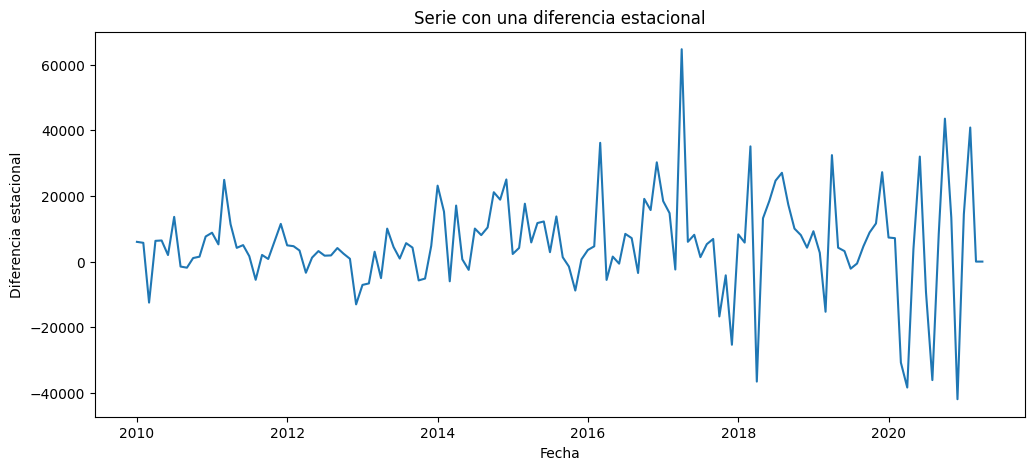

In [33]:
m = 12

y_diff_estacional = entrenamiento.diff(12)

plt.figure(figsize=(12, 5))
plt.plot(y_diff_estacional)
plt.title("Serie con una diferencia estacional")
plt.xlabel("Fecha")
plt.ylabel("Diferencia estacional")
plt.show()

La serie logra estabilizarse en media con una diferencia estacional.

### Elección del parámetro P y Q.

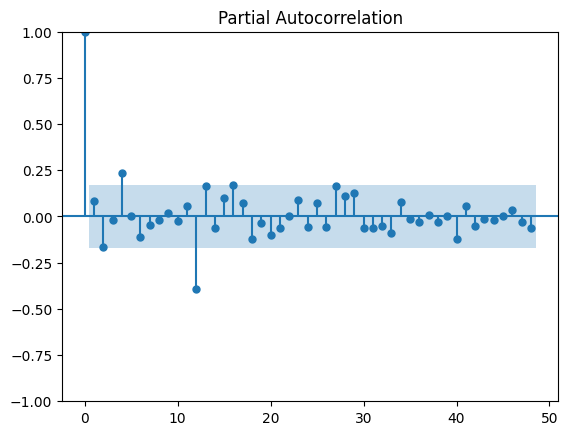

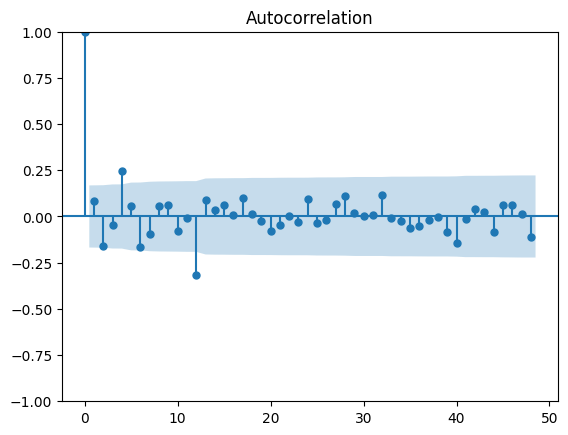

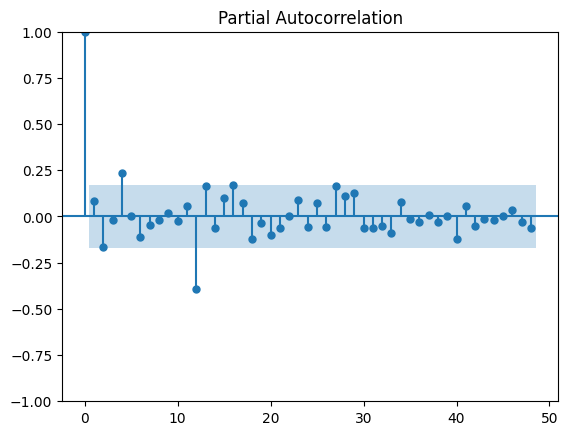

In [34]:
plot_acf(entrenamiento.diff(12).dropna(), lags=48)
plot_pacf(entrenamiento.diff(12).dropna(), lags=48)

El PACF y el ACF caen en el primer retardo.

### Elección de parámetros.

- d = 1. Debido a que las pruebas de estacionariedad demostraron media estacionaria después de una diferenciación.
- p = 4. Ya que el quinto retardo deja de ser significativo en el PACF.
- q = 0. Ya que el tercer retardo deja de ser significativo en el ACF.
- D = 1. Ya que la serie se estabiliza en media con una diferencia estacional.
- P = 0. Ya que el primer retardo no es significativo.
- Q = 0. Ya que el primer retardo no es significativo.

### Entrenamiento de modelos SARIMA.

In [35]:
modelo_1 = SARIMAX(entrenamiento_transformado, order=(4, 1, 0), seasonal_order=(0, 1, 0, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_1 = modelo_1.fit(maxiter=500, disp=False)

In [36]:
modelo_2 = SARIMAX(entrenamiento_transformado, order=(2, 1, 0), seasonal_order=(0, 1, 0, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_2 = modelo_2.fit(maxiter=500, disp=False)

In [37]:
modelo_3 = SARIMAX(entrenamiento_transformado, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_3 = modelo_3.fit(maxiter=500, disp=False)

### Comparación de los modelos.

In [38]:
modelos = {"SARIMA 1": sarima_1, "SARIMA 2": sarima_2, "SARIMA 3": sarima_3}

resultados = []

for nombre, modelo in modelos.items():
    residuos = modelo.resid.dropna()

    ljung_box = acorr_ljungbox(residuos, lags=[12], return_df=True)
    resultados.append({"Modelo": nombre, "AIC": modelo.aic, "BIC": modelo.bic, "Media residuos": residuos.mean(), 
                       "Ljung-Box p-value": ljung_box["lb_pvalue"].iloc[0]})

comparacion = pd.DataFrame(resultados).sort_values(by=["AIC", "BIC"])

print(comparacion)

     Modelo          AIC          BIC  Media residuos  Ljung-Box p-value
2  SARIMA 3  2662.801048  2676.780001    -1023.010262       5.952624e-04
0  SARIMA 1  2902.254545  2916.630532      158.244981       4.082132e-05
1  SARIMA 2  2975.532329  2984.203376      110.707056       3.829958e-09


El SARIMA 3 demostró ser mejor modelo teniendo un AIC, BIC menor que el de los otros. La media es en magnitud mucho más grande que el de los otros. Todos cumplen con la independencia de residuos ya que los valores p son menores a 0.05.  
Se eligirá el SARIMA 3 debido a su AIC y BIC menores.

### Otros modelos.

In [39]:
# Período de predicción.
periodo_estacional = 12

# Función que evalúa las métricas.
def metricas(y_real, y_pred):
    return {'MAE': mean_absolute_error(y_real, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_real, y_pred))}
predicciones = {}

In [40]:
# Métricas de los modelos SARIMA
modelos_sarima = {
    'SARIMA 1': sarima_1,
    'SARIMA 2': sarima_2,
    'SARIMA 3': sarima_3
}

for nombre, modelo in modelos_sarima.items():
    predicciones[nombre] = modelo.forecast(steps=len(prueba))

In [41]:
# Prophet
prophet_train = pd.DataFrame({'ds': entrenamiento_transformado.index,
                              'y': entrenamiento_transformado['Viajero']})

modelo_prophet = Prophet()
modelo_prophet.fit(prophet_train)
futuro = pd.DataFrame({'ds': prueba.index})
predicciones['Prophet'] = modelo_prophet.predict(futuro)['yhat'].values

19:57:41 - cmdstanpy - INFO - Chain [1] start processing
19:57:41 - cmdstanpy - INFO - Chain [1] done processing


In [42]:
# Holt-Winters
modelo_hw = ExponentialSmoothing(entrenamiento_transformado, trend="add", seasonal="add", seasonal_periods=periodo_estacional).fit()
predicciones["Holt-Winters"] = modelo_hw.forecast(len(prueba))

In [43]:
# Suavizamiento exponencial simple
modelo_ses = SimpleExpSmoothing(entrenamiento_transformado).fit(optimized=True)
predicciones["Suavizamiento exponencial"] = modelo_ses.forecast(len(prueba))

In [44]:
# Seasonal Naive
predicciones["Seasonal Naive"] = np.resize(entrenamiento_transformado.iloc[-periodo_estacional:].values, len(prueba))

In [45]:
# Comparación
resultados = []

for nombre, prediccion in predicciones.items():
    valores = metricas(prueba.values, np.asarray(prediccion))

    resultados.append({
        "Modelo": nombre,
        "MAE": valores["MAE"],
        "RMSE": valores["RMSE"],
        "AIC": modelos_sarima[nombre].aic
        if nombre in modelos_sarima else np.nan,
        "BIC": modelos_sarima[nombre].bic
        if nombre in modelos_sarima else np.nan
    })

comparacion = pd.DataFrame(resultados).sort_values("RMSE")

print(comparacion)
print("\nMejor modelo:", comparacion.iloc[0]["Modelo"])

                      Modelo           MAE          RMSE          AIC  \
2                   SARIMA 3  17001.616641  21211.217551  2662.801048   
4               Holt-Winters  17397.924536  21675.379044          NaN   
3                    Prophet  18412.671049  22377.219065          NaN   
5  Suavizamiento exponencial  23805.307949  30969.200392          NaN   
1                   SARIMA 2  24315.380082  31305.746922  2975.532329   
0                   SARIMA 1  26431.129112  34436.575642  2902.254545   
6             Seasonal Naive  22733.145161  34961.705566          NaN   

           BIC  
2  2676.780001  
4          NaN  
3          NaN  
5          NaN  
1  2984.203376  
0  2916.630532  
6          NaN  

Mejor modelo: SARIMA 3


### Elección del mejor modelo.

In [46]:
# Predicción del mejor modelo
indice = 0
mejor_modelo_nombre = comparacion.iloc[indice]["Modelo"]
print('Se selecciona el modelo:', mejor_modelo_nombre)
mejor_modelo = sarima_1

Se selecciona el modelo: SARIMA 3


Esto debido a que tiene menor RMSE y MAE que todos los demás modelos y teniendo mejor AIC y BIC que los otros SARIMA.

### Gráfica de predicción.

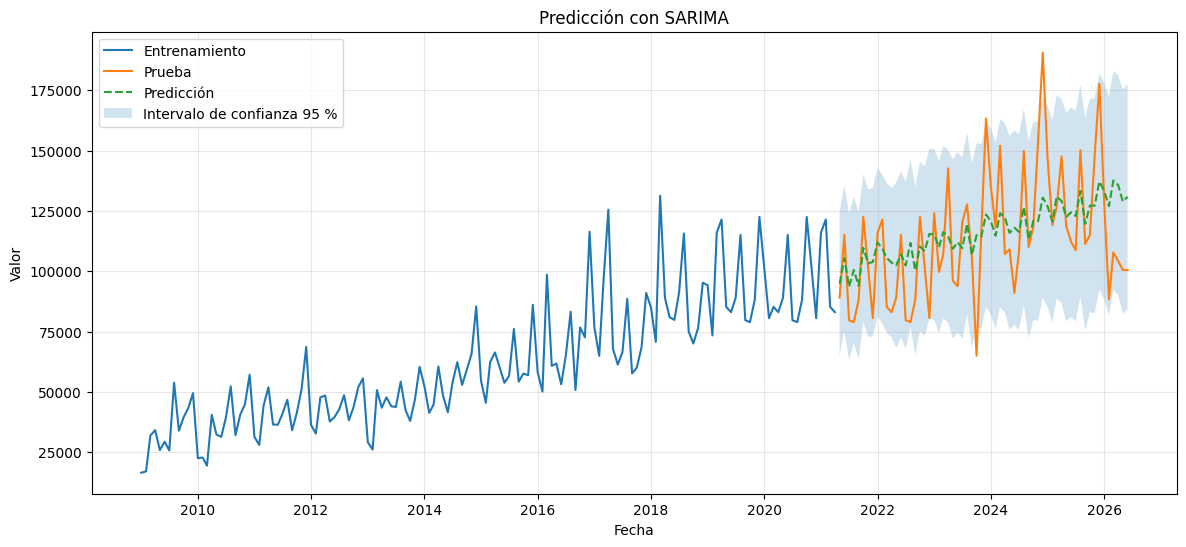

In [47]:
# Predicción e intervalos de confianza
pronostico_sarima = sarima_3.get_forecast(steps=len(prueba))
prediccion_sarima = pronostico_sarima.predicted_mean
intervalos = pronostico_sarima.conf_int(alpha=0.05)

limite_inferior = intervalos.iloc[:, 0]
limite_superior = intervalos.iloc[:, 1]

# Ajustar el índice al conjunto de prueba
prediccion_sarima.index = prueba.index
limite_inferior.index = prueba.index
limite_superior.index = prueba.index

# Gráfica
plt.figure(figsize=(14, 6))
plt.plot(entrenamiento.index, entrenamiento, label="Entrenamiento")
plt.plot(prueba.index, prueba, label="Prueba")
plt.plot(prueba.index, prediccion_sarima, linestyle="--", label="Predicción")
plt.fill_between(prueba.index, limite_inferior, limite_superior, alpha=0.2, label="Intervalo de confianza 95 %")
plt.title("Predicción con SARIMA")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

El modelo SARIMA, logra seguir la tendencia de las visitas turísticas, pero tiene problemas con la varianza de los datos, ya que no se consiguió que el conjunto fuera estacionario en varianza. Incluso el intervalo de confianza falla para 3 puntos.